709


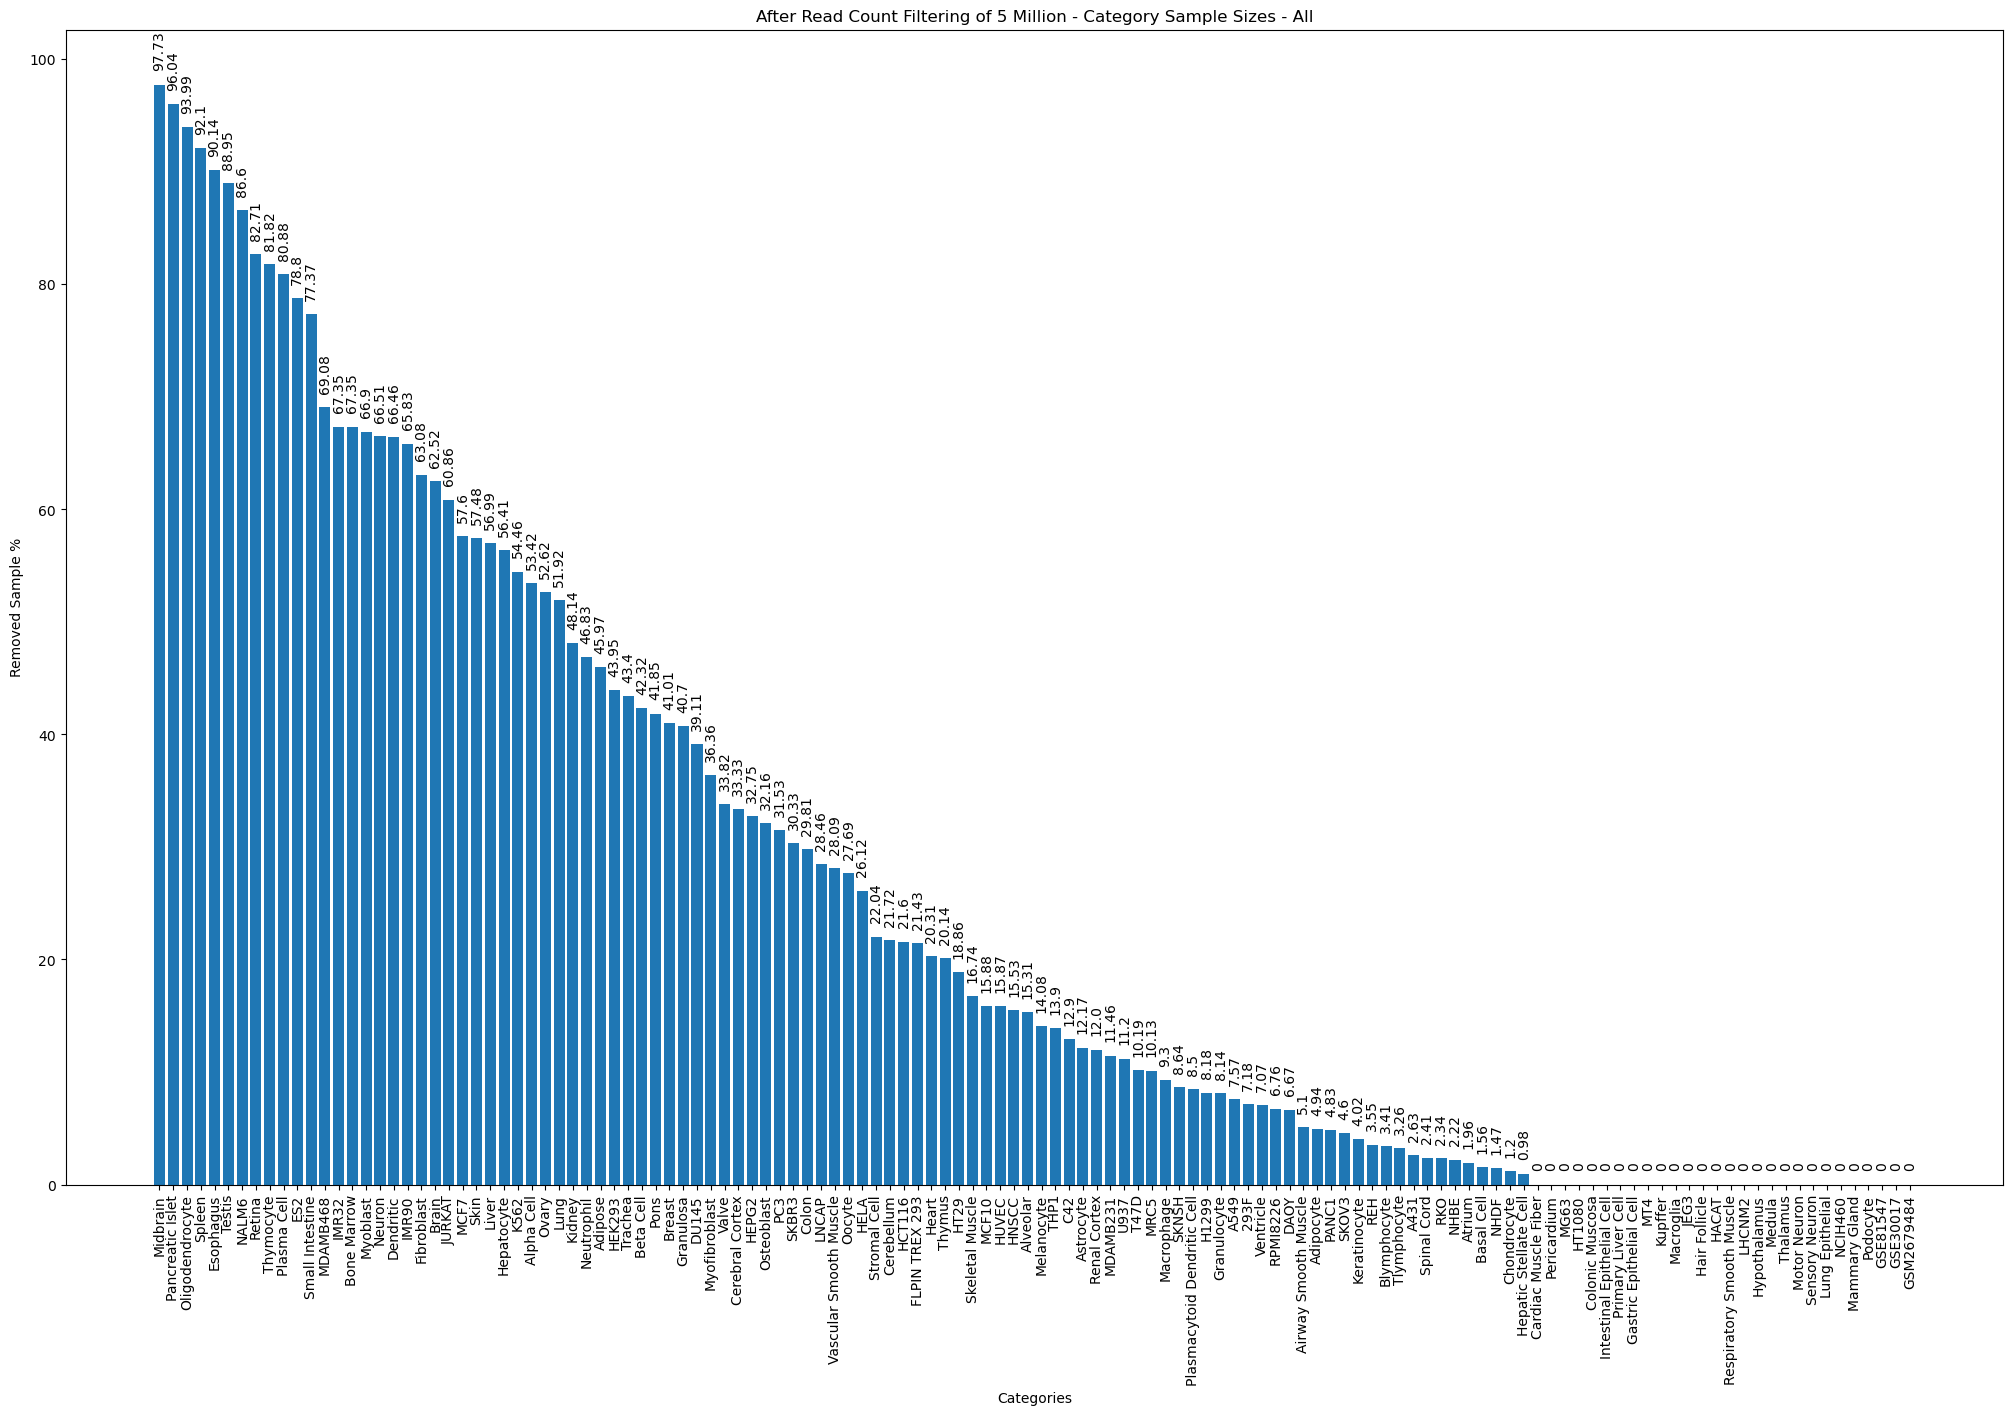

CPU times: user 1.96 s, sys: 421 ms, total: 2.38 s
Wall time: 2.27 s


In [28]:
%%time
import json
import matplotlib.pyplot as plt

# Load the data from the .json file
with open('/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/results/category_uniqueSampleSizes_dict_LW20230121.json', 'r') as f:
    org_biosamples_dict = json.load(f)

# Print the value of the key 'key1'
print(org_biosamples_dict['Heart'])

# ------------------------------------------------------------------------------------------------------------- #
with open("filtered_category_uniqueSampleSizes_dict_LW20230123.json", "r") as f:
    filtered_sampleSize = json.load(f)

############################################# DIFF CALC# #######################################################
# Get the difference
import operator
sampleSize_diff = {}

for key in org_biosamples_dict:
    if key in filtered_sampleSize:
        remaining_samples = org_biosamples_dict[key] - filtered_sampleSize[key]
        if remaining_samples != 0:
            sampleSize_diff[key] = remaining_samples/org_biosamples_dict[key]
        else:
            sampleSize_diff[key] = 0

# sort the result dictionary in descending order based on the values
sorted_sampleSize_diff = dict(sorted(sampleSize_diff.items(), key=operator.itemgetter(1), reverse=True))

############################################# PLOT CALC ########################################################
# get the keys and values from the sorted result dictionary
keys = list(sorted_sampleSize_diff.keys())
values = list(sorted_sampleSize_diff.values())

# convert to percentage
values = [v * 100 for v in values]

# get the keys and values from the sorted result dictionary
keys = list(sorted_sampleSize_diff.keys())
values = list(sorted_sampleSize_diff.values())

# convert to percentage
values = [v * 100 for v in values]

# Add the value labels
for i, v in enumerate(values):
    plt.annotate(str(round(v, 2)), xy=(i,v), xytext=(0,10), textcoords='offset points', ha='center', va='bottom', rotation = 90)

# create the bar plot
plt.bar(keys, values)
plt.xlabel('Categories')
plt.xticks(rotation=90)
fig = plt.gcf()
fig.set_size_inches(25, 15)
plt.ylabel('Removed Sample %')
plt.title('After Read Count Filtering of 5 Million - Category Sample Sizes - All')
plt.show()

Data loaded******
Data Calculated******


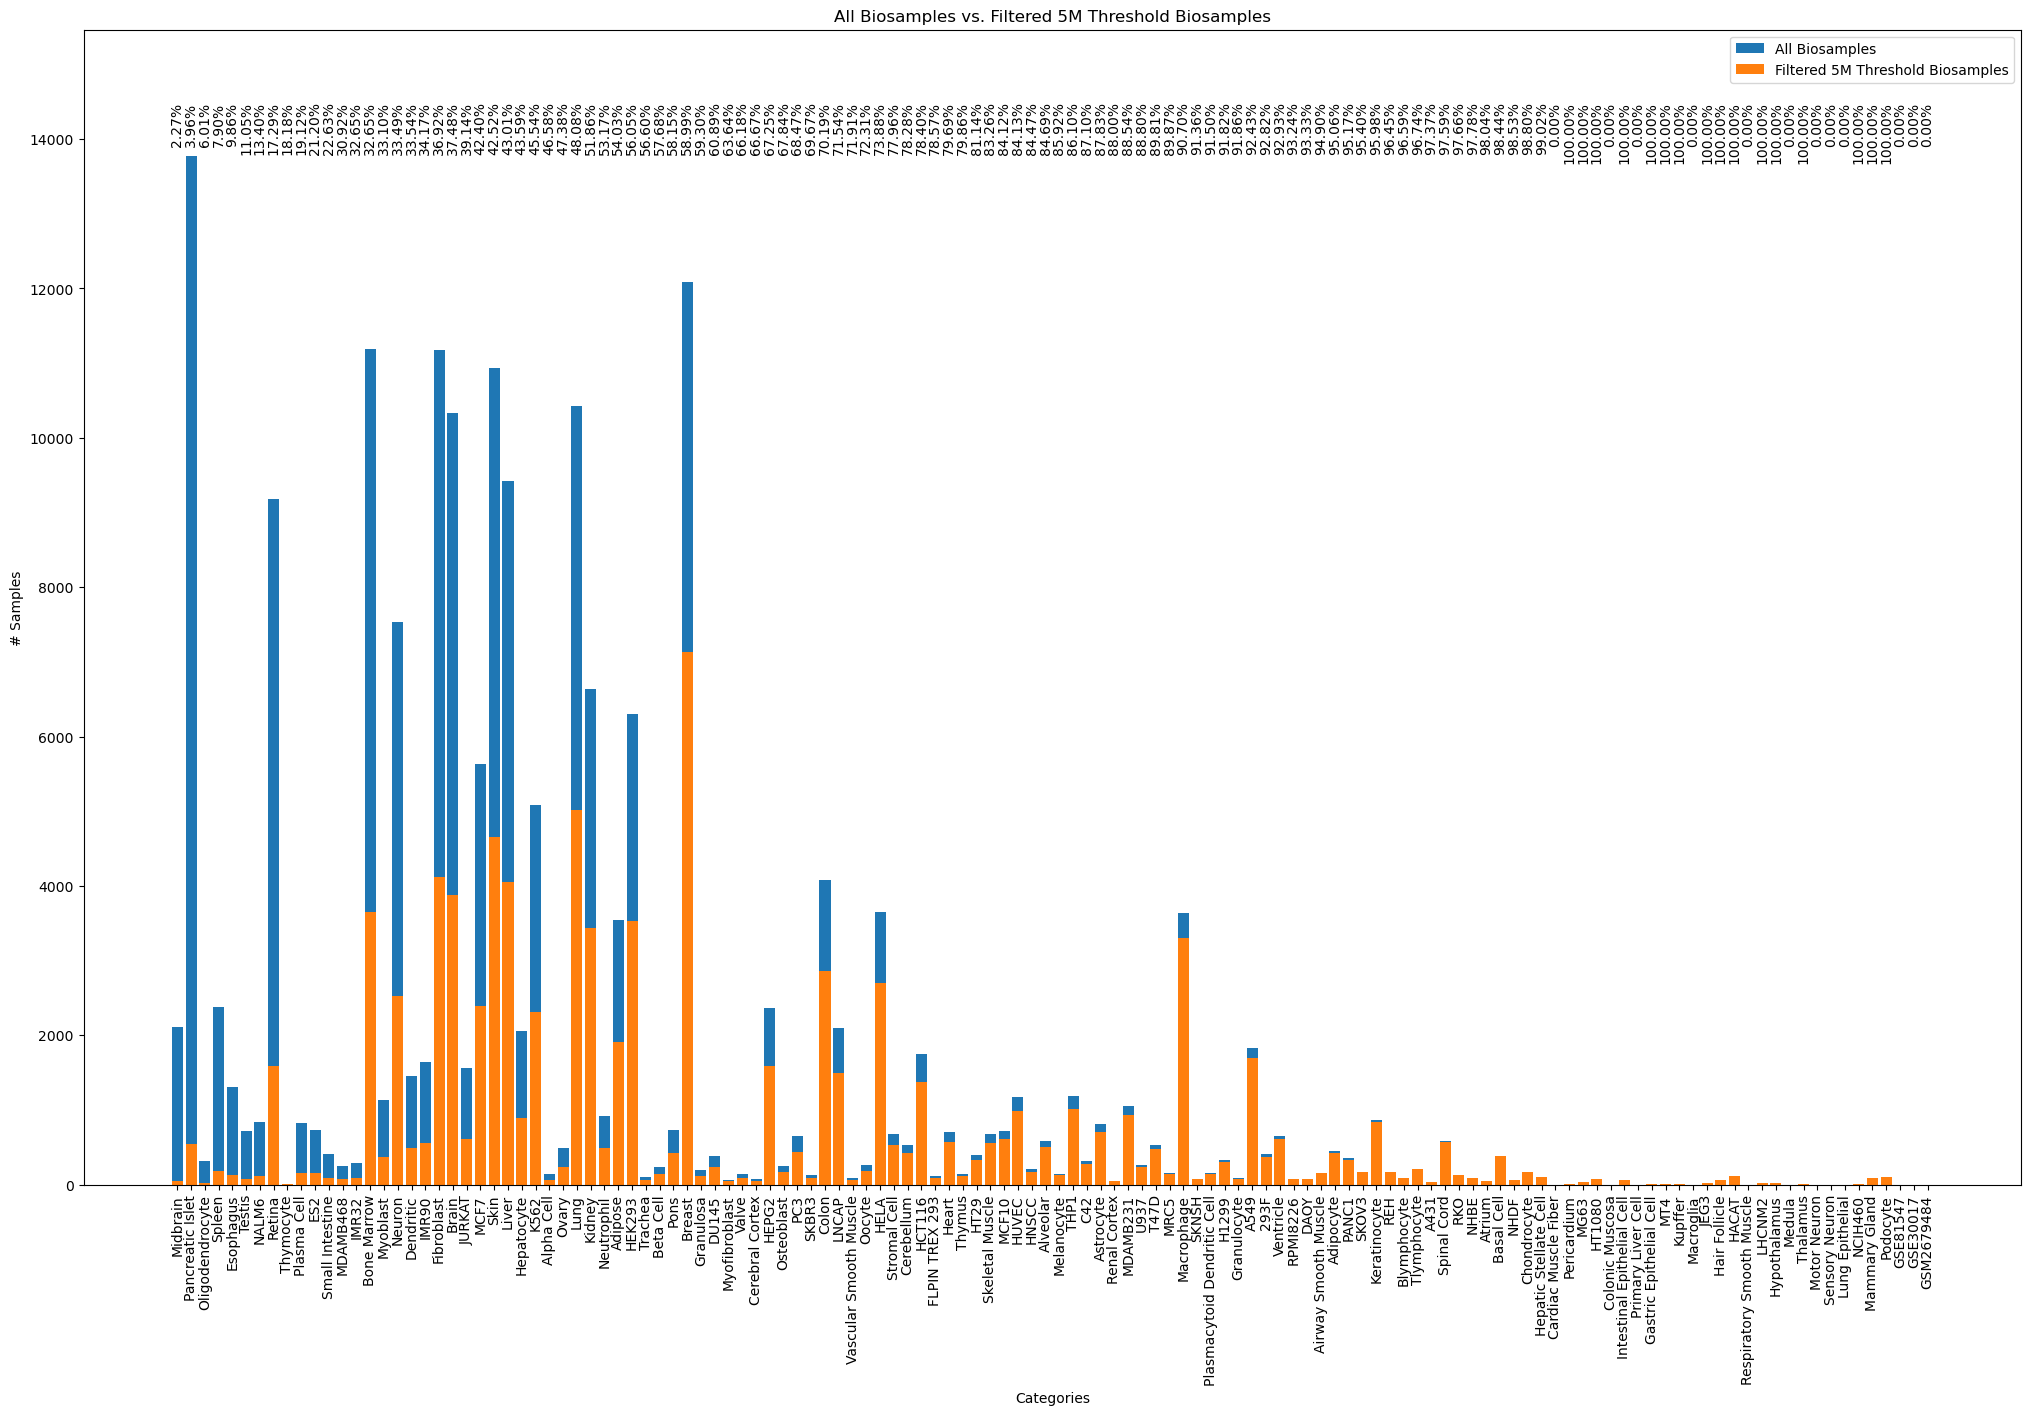

CPU times: user 2.06 s, sys: 462 ms, total: 2.52 s
Wall time: 2.41 s


In [29]:
%%time
import json
import matplotlib.pyplot as plt

# Load the data from the .json file
with open('/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/sbatch_files/results/category_uniqueSampleSizes_dict_LW20230121.json', 'r') as f:
    org_biosamples_dict = json.load(f)

# Print the value of the key 'key1'
#print(org_biosamples_dict['Heart'])

######
with open("filtered_category_uniqueSampleSizes_dict_LW20230123.json", "r") as f:
    filtered_sampleSize = json.load(f)

print("Data loaded******")
################################################################################################################

# Get the keys from both dictionaries
categories_list = list(org_biosamples_dict.keys())

# Get the values from both dictionaries
org_biosamples_values = [org_biosamples_dict[key] for key in categories_list]
filtered_biosamples_values = [filtered_sampleSize[key] for key in categories_list]

ordered_list = keys

# Create a dictionary from categories_list and org_biosamples_values
org_biosamples_dict = dict(zip(categories_list, org_biosamples_values))
filtered_sampleSize = dict(zip(categories_list, filtered_biosamples_values))

# Get the keys from both dictionaries
categories_list = list(org_biosamples_dict.keys())

# Get the values from both dictionaries
org_biosamples_values = [org_biosamples_dict[key] for key in ordered_list]
filtered_biosamples_values = [filtered_sampleSize[key] for key in ordered_list]

# Create a list of tuples containing the keys, values from dict1, and values from dict2
data = list(zip(ordered_list, org_biosamples_values, filtered_biosamples_values))
#print(data)


print("Data Calculated******")
################################################################################################################

# Unpack the tuples into separate lists
keys_cat, dict1_values, dict2_values = zip(*data)

# Create the bar plot
fig, ax = plt.subplots()


# Create the bars for dict2 values
bars = ax.bar(range(1, len(keys_cat) + 1), dict1_values, label='All Biosamples')
ax.bar(range(1, len(keys_cat) + 1), dict2_values, label='Filtered 5M Threshold Biosamples')

# Create the bars for dict1 values with transparency
#ax.bar(range(1, len(categories_list) + 1), dict1_values, label='Filtered 5M Threshold Biosamples')

# # Create the bars for dict2 values
# bars = ax.bar(range(1, len(categories_list) + 1), dict2_values, label='All Biosamples')

# # Create the stacked bars
# bars = ax.bar(range(1, len(categories_list) + 1), dict2_values, bottom=dict1_values, label='All Biosamples')
# ax.bar(range(1, len(categories_list) + 1), dict1_values, label='Filtered 5M Threshold Biosamples')


# Get the current y-axis limits
ymin, ymax = plt.ylim()

# Extend the y-axis by 10 units above the maximum value
plt.ylim(ymin, ymax+1000)

# Add the difference percentage labels on top of each bar
for i, bar in enumerate(bars):
    if dict1_values[i] == 0:
        diff_percent = 0.0
    else:
        diff_percent = (dict2_values[i] / (dict1_values[i] + 0.0001)) * 100
        
    ax.text(bar.get_x() + bar.get_width() / 2, 14500 , '{:.2f}%'.format(diff_percent), ha='center', va='top', rotation = 90)

# Set x-tick labels
ax.set_xticks(range(1, len(keys) + 1))
ax.set_xticklabels(keys, rotation = 90)

# Add labels and legend
plt.xlabel('Categories')
fig = plt.gcf()
fig.set_size_inches(25, 15)
plt.ylabel('# Samples')
plt.title('All Biosamples vs. Filtered 5M Threshold Biosamples')
plt.legend()

# Show the plot
plt.show()


In [26]:
# Adjust spacing between subplots
plt.subplots_adjust(hspace=0.4)
plt.show()

<Figure size 640x480 with 0 Axes>

# TEST CODE

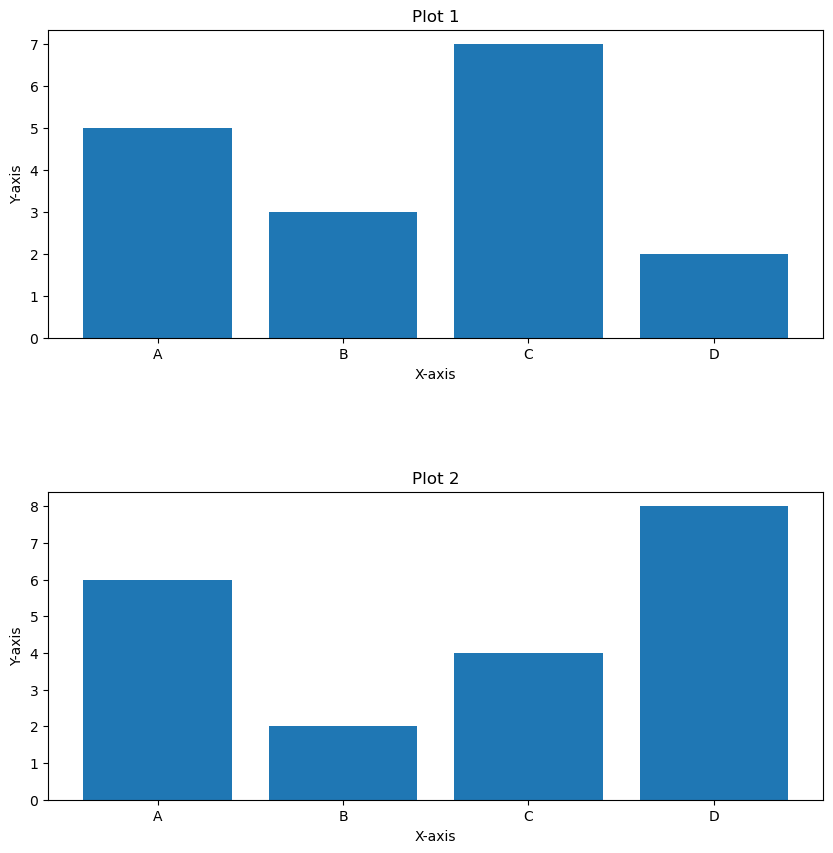

In [1]:
import matplotlib.pyplot as plt

# Dummy data
plot1 = {'A':5, 'B':3, 'C':7, 'D':2}
plot2 = {'C':4, 'A':6, 'B':2, 'D':8}

# Create figure and specify subplot layout
fig = plt.figure(figsize=(10,10))
plt.subplots_adjust(wspace=0.5, hspace=0.5)

x_keys = list(plot1.keys())

ax1 = plt.subplot(2, 1, 1)
ax1.bar(x_keys, [plot1[key] for key in x_keys])
ax1.set_xlabel("X-axis")
ax1.set_ylabel("Y-axis")
ax1.set_title("Plot 1")

ax2 = plt.subplot(2, 1, 2)
ax2.bar(x_keys, [plot2[key] for key in x_keys])
ax2.set_xlabel("X-axis")
ax2.set_ylabel("Y-axis")
ax2.set_title("Plot 2")

plt.show()


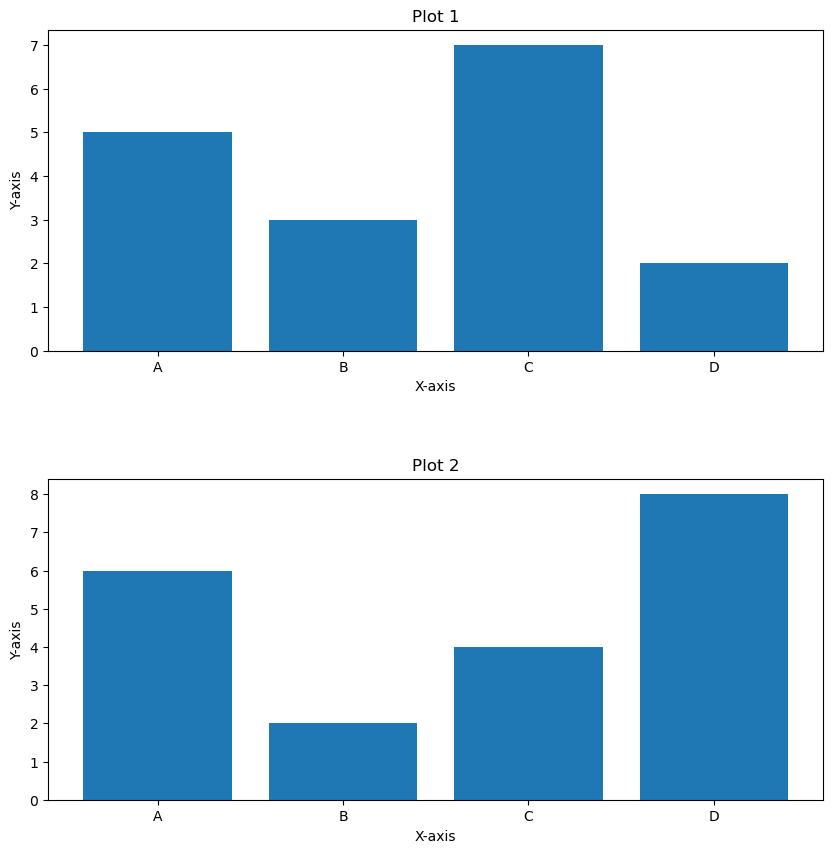

In [16]:
from collections import OrderedDict

# Dummy data
plot1 = {'A':5, 'B':3, 'C':7, 'D':2}
plot2 = {'C':4, 'A':6, 'B':2, 'D':8}

# Create a new dictionary with the key-value pairs of plot2 in the order of keys in plot1
plot2_rearranged = OrderedDict((k, plot2[k]) for k in plot1.keys())

# Create figure and specify subplot layout
fig = plt.figure(figsize=(10,10))

# Create first subplot
ax1 = plt.subplot(2, 1, 1)
ax1.bar(plot1.keys(), plot1.values())
ax1.set_xlabel("X-axis")
ax1.set_ylabel("Y-axis")
ax1.set_title("Plot 1")

# Create second subplot and align it with the first
ax2 = plt.subplot(2, 1, 2)
ax2.bar(plot2_rearranged.keys(), plot2_rearranged.values())
ax2.set_xlabel("X-axis")
ax2.set_ylabel("Y-axis")
ax2.set_title("Plot 2")

# Adjust spacing between subplots
plt.subplots_adjust(hspace=0.4)
plt.show()


In [17]:
categories_list = ["Midbrain", "Heart", "Eyes"]
org_biosamples_values = [0, 10, 20]
filtered_biosamples_values = [0, 8, 4]
ordered_list = ["Midbrain", "Eyes", "Heart"]

# Create a dictionary from categories_list and org_biosamples_values
org_biosamples_dict = dict(zip(categories_list, org_biosamples_values))
filtered_sampleSize = dict(zip(categories_list, filtered_biosamples_values))

# Get the keys from both dictionaries
categories_list = list(org_biosamples_dict.keys())

# Get the values from both dictionaries
org_biosamples_values = [org_biosamples_dict[key] for key in ordered_list]
filtered_biosamples_values = [filtered_sampleSize[key] for key in ordered_list]

# Create a list of tuples containing the keys, values from dict1, and values from dict2
data = list(zip(ordered_list, org_biosamples_values, filtered_biosamples_values))
print(data)


[('Midbrain', 0, 0), ('Eyes', 20, 4), ('Heart', 10, 8)]
